In [27]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/kerala_water_quality.csv")

df["Data Acquisition Time"] = pd.to_datetime(
    df["Data Acquisition Time"],
    errors="coerce"
)

print("Dataset shape:", df.shape)
print("Date column type:", df["Data Acquisition Time"].dtype)


Dataset shape: (1155, 22)
Date column type: datetime64[us]


In [28]:
df.columns


Index(['_id', 'SlNo', 'Station', 'Agency', 'State LGD Code', 'State',
       'District LGD Code', 'District', 'Tehsil', 'River', 'Basin',
       'Tributary', 'Subtributary', 'SubSubtributary', 'Local River',
       'Latitude', 'Longitude', 'Data Acquisition Time',
       'Biochemical Oxygen Demand (mg/L)', 'Chemical Oxygen Demand (mg/L)',
       'Fecal Coliform (MPN/100mL)', 'Total Coliform (MPN/100mL)'],
      dtype='str')

In [29]:
df["Station"].nunique()


129

In [30]:
df[[
    "Biochemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]].describe()

,Biochemical Oxygen Demand (mg/L),Fecal Coliform (MPN/100mL),Total Coliform (MPN/100mL)
count,656.000000,883.000000,293.000000
mean,2.211280,823.537939,3412.443686
std,1.268428,3223.587417,13805.449667
min,1.100000,4.000000,12.000000
25%,1.500000,79.000000,240.000000
50%,1.900000,130.000000,620.000000
75%,2.400000,490.000000,2200.000000
max,8.200000,70000.000000,200000.000000


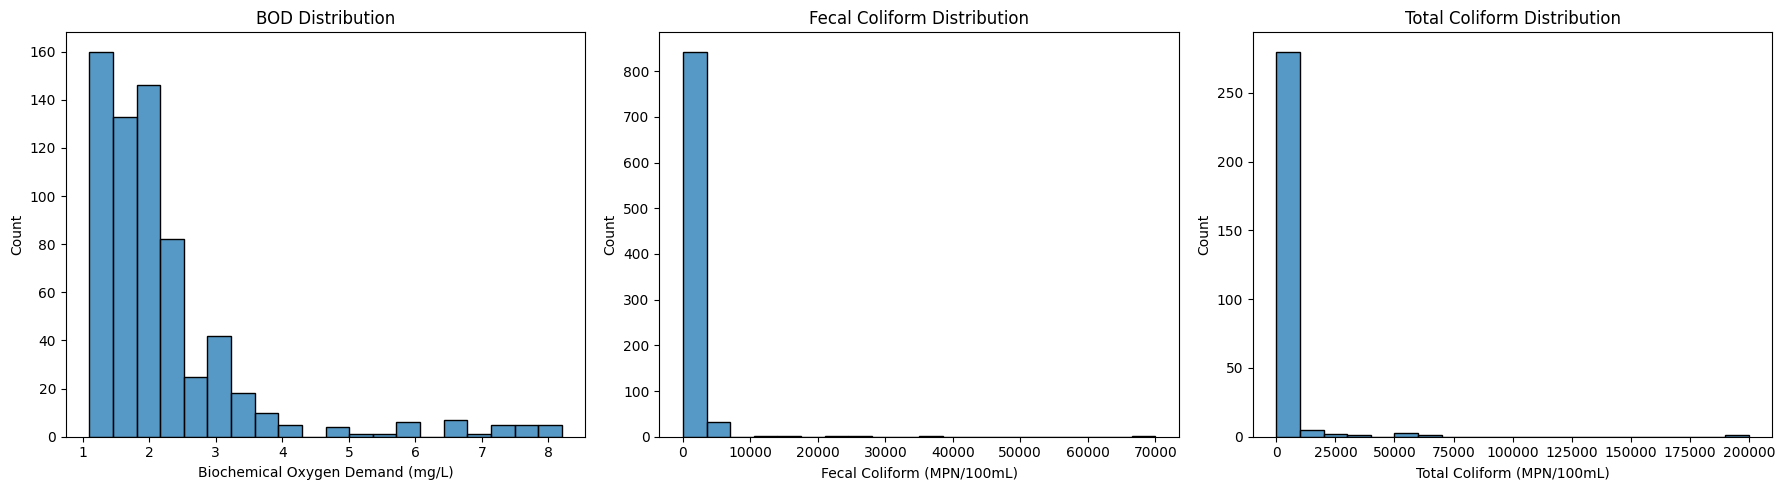

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["Biochemical Oxygen Demand (mg/L)"], bins=20, ax=axes[0])
axes[0].set_title("BOD Distribution")

sns.histplot(df["Fecal Coliform (MPN/100mL)"], bins=20, ax=axes[1])
axes[1].set_title("Fecal Coliform Distribution")

sns.histplot(df["Total Coliform (MPN/100mL)"], bins=20, ax=axes[2])
axes[2].set_title("Total Coliform Distribution")

plt.tight_layout()
plt.show()

In [32]:
district_bod = df.groupby("District")[
    "Biochemical Oxygen Demand (mg/L)"
].mean().sort_values(ascending=False)

district_bod

District
THIRUVANANTHAPURAM    3.691489
KOTTAYAM              2.420000
Alappuzha             2.234783
ERNAKULAM             2.208661
Kollam                2.141818
PATHANAMTHITTA        2.005000
PALAKKAD              1.901754
THRISSUR              1.768000
IDUKKI                1.766667
MALAPPURAM            1.726923
KOZHIKODE             1.719231
KASARAGOD             1.706522
KANNUR                1.564865
WAYANAD               1.340000
Name: Biochemical Oxygen Demand (mg/L), dtype: float64

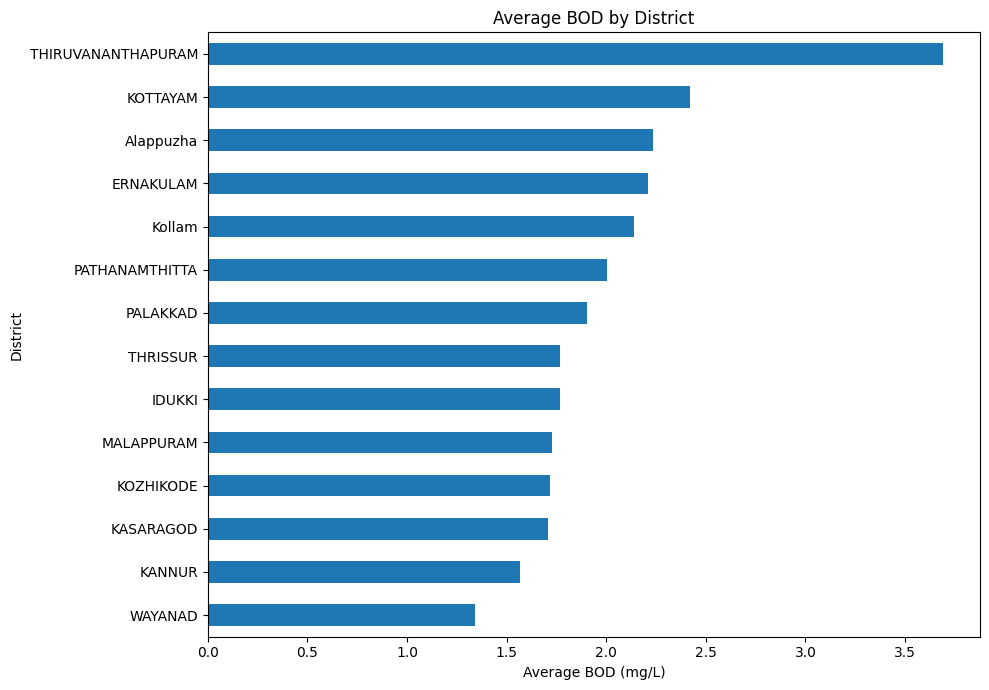

In [33]:
import matplotlib.pyplot as plt

district_bod.sort_values().plot(kind="barh", figsize=(10, 7))

plt.title("Average BOD by District")
plt.xlabel("Average BOD (mg/L)")
plt.ylabel("District")
plt.tight_layout()
plt.show()

In [34]:
district_fecal = df.groupby("District")[
    "Fecal Coliform (MPN/100mL)"
].mean().sort_values(ascending=False)

district_fecal

District
KOZHIKODE             4442.311688
IDUKKI                2371.666667
ERNAKULAM             1105.183007
THIRUVANANTHAPURAM     893.421053
KOTTAYAM               497.307692
MALAPPURAM             487.533333
THRISSUR               413.109091
PALAKKAD               245.412698
PATHANAMTHITTA         238.046875
Alappuzha              118.859375
Kollam                  93.500000
KASARAGOD               85.294872
KANNUR                  61.175258
WAYANAD                 34.153846
Name: Fecal Coliform (MPN/100mL), dtype: float64

In [35]:
df["Station"].value_counts()

Station
ACHANKOVIL AT CHENNITHULA                                      12
ACHANKOVIL AT KALLARAKADAVU PATHANAMTHITTA                     12
ACHANKOVIL AT PANDALAM (NEAR AYYAPPA TEMPLE) PATHANAMTHITTA    12
ACHANKOVIL AT THUMPAMON                                        12
ALAPPUZHA KERALA                                               12
                                                               ..
WELL AT VYTTILA ERNAKULAM DISTT.  KERALA                        2
WELL OF TEMPLE PARASSINIKADAVU KANNUR                           2
WELL AT CHERTHALA ALLEPPY KERALA                                1
WELL AT OLLUR (THRISSUR)                                        1
WELL AT PUNKUNNAM TRISSUR DISTT.  KERALA                        1
Name: count, Length: 129, dtype: int64

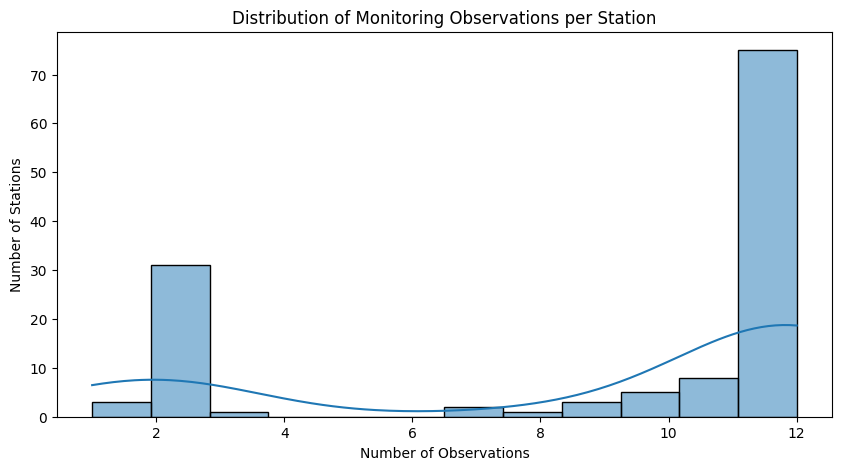

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

station_counts = df["Station"].value_counts()

plt.figure(figsize=(10, 5))

sns.histplot(station_counts, bins=12, kde=True)

plt.title("Distribution of Monitoring Observations per Station")
plt.xlabel("Number of Observations")
plt.ylabel("Number of Stations")

plt.show()

In [37]:
df["District"].value_counts()

District
ERNAKULAM             202
THIRUVANANTHAPURAM    112
KANNUR                110
KOZHIKODE             102
Alappuzha             101
PALAKKAD               85
THRISSUR               79
KASARAGOD              78
Kollam                 68
PATHANAMTHITTA         66
MALAPPURAM             60
WAYANAD                37
IDUKKI                 29
KOTTAYAM               26
Name: count, dtype: int64

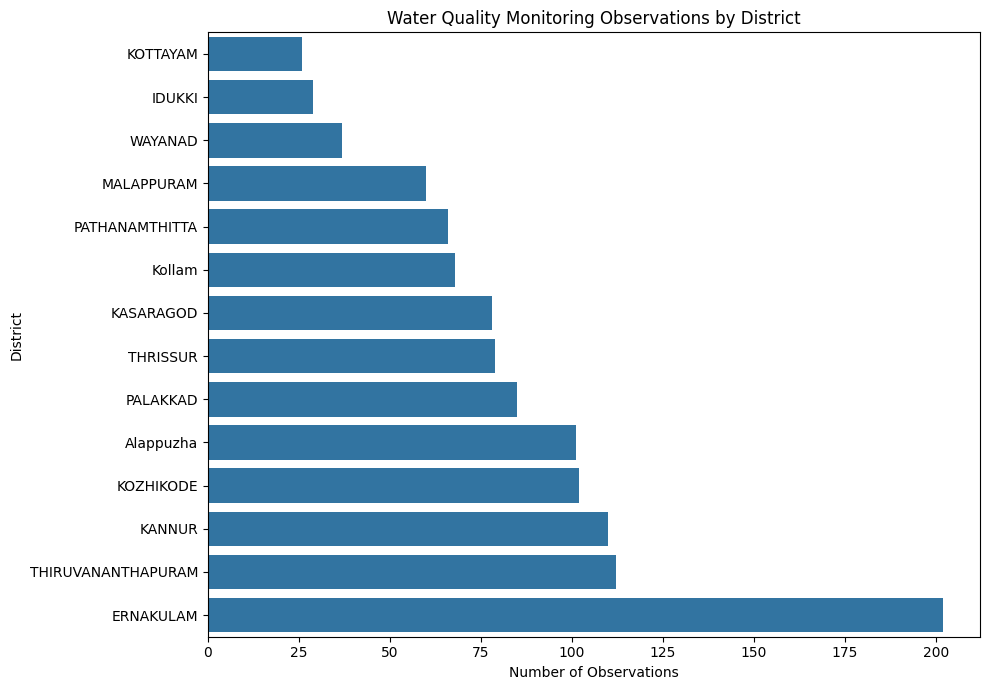

In [38]:
district_counts = df["District"].value_counts().sort_values()

plt.figure(figsize=(10, 7))

sns.barplot(x=district_counts.values, y=district_counts.index)

plt.title("Water Quality Monitoring Observations by District")
plt.xlabel("Number of Observations")
plt.ylabel("District")

plt.tight_layout()
plt.show()


In [39]:

print("Columns related to waterbody/location:")
print([
    col for col in df.columns
    if any(word in col.lower() for word in
           ["water", "river", "lake", "type", "station", "district"])
])


Columns related to waterbody/location:
['Station', 'District LGD Code', 'District', 'River', 'Local River']


In [40]:

parameters = [
    "Biochemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]

print(df[parameters].describe().T)


                                  count         mean           std   min  \
Biochemical Oxygen Demand (mg/L)  656.0     2.211280      1.268428   1.1   
Fecal Coliform (MPN/100mL)        883.0   823.537939   3223.587417   4.0   
Total Coliform (MPN/100mL)        293.0  3412.443686  13805.449667  12.0   

                                    25%    50%     75%       max  
Biochemical Oxygen Demand (mg/L)    1.5    1.9     2.4       8.2  
Fecal Coliform (MPN/100mL)         79.0  130.0   490.0   70000.0  
Total Coliform (MPN/100mL)        240.0  620.0  2200.0  200000.0  


In [41]:
print(df[parameters].isnull().sum())

Biochemical Oxygen Demand (mg/L)    499
Fecal Coliform (MPN/100mL)          272
Total Coliform (MPN/100mL)          862
dtype: int64


In [42]:
print("Dataset shape:", df.shape)

print("\nMissing values by column:")
print(df.isnull().sum())

Dataset shape: (1155, 22)

Missing values by column:
_id                                    0
SlNo                                   0
Station                                0
Agency                                 0
State LGD Code                         0
State                                  0
District LGD Code                      0
District                               0
Tehsil                                 0
River                                  0
Basin                                  0
Tributary                              0
Subtributary                           0
SubSubtributary                        0
Local River                            0
Latitude                               0
Longitude                              0
Data Acquisition Time                364
Biochemical Oxygen Demand (mg/L)     499
Chemical Oxygen Demand (mg/L)       1155
Fecal Coliform (MPN/100mL)           272
Total Coliform (MPN/100mL)           862
dtype: int64


In [43]:
bod_time = df.dropna(
    subset=["Biochemical Oxygen Demand (mg/L)"]
).copy()

bod_time["Month"] = bod_time["Data Acquisition Time"].dt.month

monthly_bod = bod_time.groupby("Month")[
    "Biochemical Oxygen Demand (mg/L)"
].mean()


In [44]:
monthly_bod

Month
1.0     2.181081
2.0     1.981633
3.0     2.396296
4.0     2.020408
5.0     2.103390
6.0     2.564444
7.0     2.329730
8.0     2.525641
9.0     2.388889
10.0    1.947826
11.0    2.050000
12.0    2.775000
Name: Biochemical Oxygen Demand (mg/L), dtype: float64

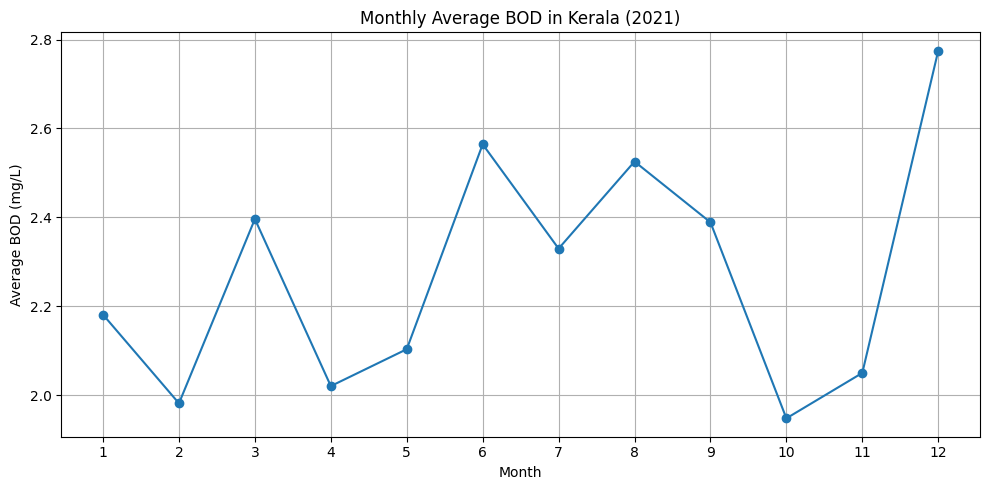

In [45]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_bod.index,
    monthly_bod.values,
    marker="o"
)

plt.title("Monthly Average BOD in Kerala (2021)")
plt.xlabel("Month")
plt.ylabel("Average BOD (mg/L)")
plt.xticks(range(1, 13))
plt.grid(True)

plt.tight_layout()
plt.show()



### Monthly BOD Analysis

Monthly average BOD values fluctuated during 2021, ranging approximately from 1.95 mg/L in October to 2.78 mg/L in December. June and August also recorded relatively higher averages. No consistent increasing or decreasing trend was observed. These results describe the available measurements and may be influenced by differences in monitoring-station coverage across months.


In [46]:
fc_time = df.dropna(
    subset=["Fecal Coliform (MPN/100mL)"]
).copy()

fc_time["Month"] = fc_time["Data Acquisition Time"].dt.month

monthly_fc = fc_time.groupby("Month")[
    "Fecal Coliform (MPN/100mL)"
].median()

monthly_fc

Month
1.0     110.0
2.0     150.0
3.0     120.0
4.0     120.0
5.0     100.0
6.0     170.0
7.0     145.0
8.0     105.0
9.0     160.0
10.0    120.0
11.0    300.0
12.0    185.0
Name: Fecal Coliform (MPN/100mL), dtype: float64

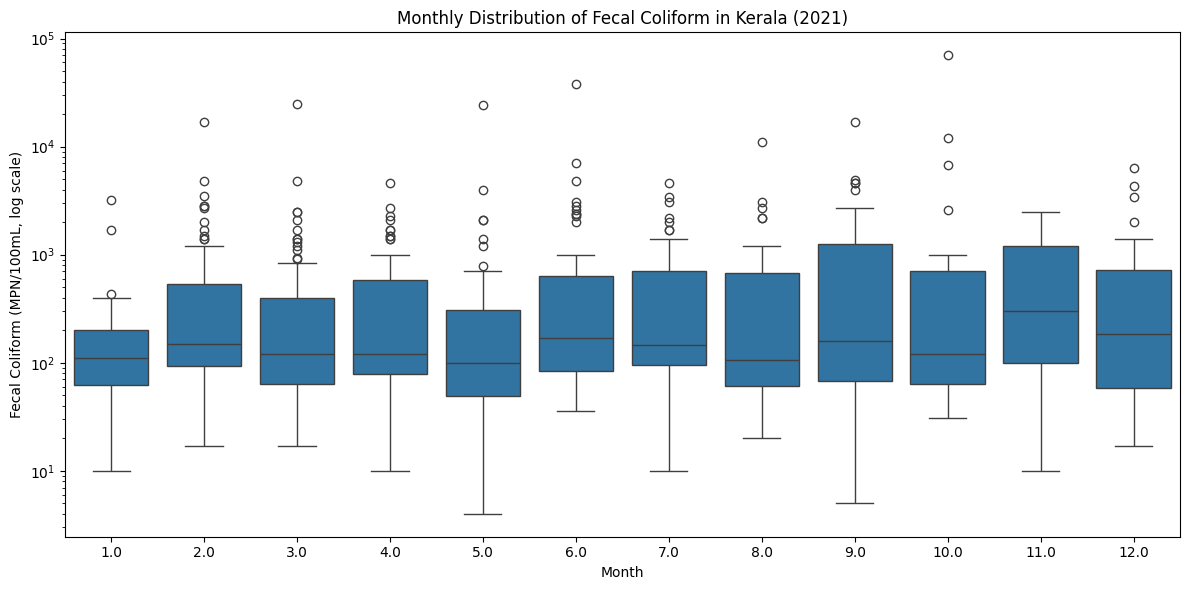

In [47]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=fc_time,
    x="Month",
    y="Fecal Coliform (MPN/100mL)"
)

plt.yscale("log")
plt.title("Monthly Distribution of Fecal Coliform in Kerala (2021)")
plt.xlabel("Month")
plt.ylabel("Fecal Coliform (MPN/100mL, log scale)")
plt.tight_layout()
plt.show()


### Monthly Fecal Coliform Analysis

The monthly boxplot reveals substantial variability in Fecal Coliform measurements throughout 2021. Median concentrations generally remained within approximately 100–200 MPN/100mL, although November showed a comparatively higher median. High-value observations occurred in every month, including an observation of approximately 70,000 MPN/100mL in October. The logarithmic scale was used to represent the wide range of measurements. These patterns require further investigation during refined EDA.

In [48]:

tc_time = df.dropna(
    subset=["Total Coliform (MPN/100mL)"]
).copy()

tc_time["Month"] = tc_time["Data Acquisition Time"].dt.month


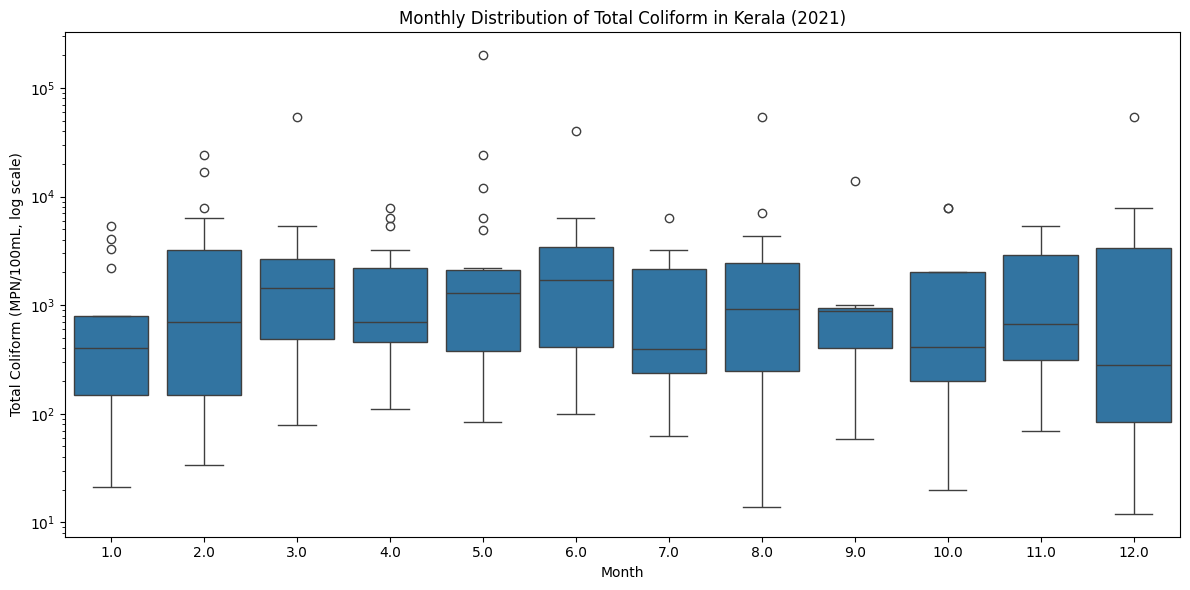

In [49]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=tc_time,
    x="Month",
    y="Total Coliform (MPN/100mL)"
)

plt.yscale("log")
plt.title("Monthly Distribution of Total Coliform in Kerala (2021)")
plt.xlabel("Month")
plt.ylabel("Total Coliform (MPN/100mL, log scale)")
plt.tight_layout()
plt.show()



### Monthly Total Coliform Analysis

The monthly boxplot indicates considerable variability in Total Coliform measurements throughout 2021. March, May, and June exhibited comparatively higher median concentrations, while January and July showed lower medians. High-value observations were present in several months, including a measurement exceeding 100,000 MPN/100mL in May. The logarithmic scale helps visualize the wide range of values. Since approximately 74.6% of TC measurements are missing, these findings represent only the available observations and require cautious interpretation.


### Correlation Analysis

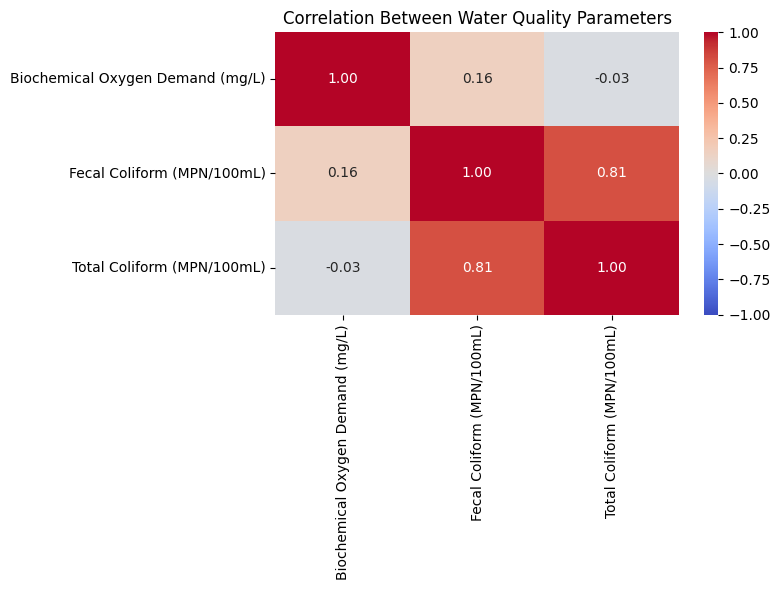

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_data = df[
    [
        "Biochemical Oxygen Demand (mg/L)",
        "Fecal Coliform (MPN/100mL)",
        "Total Coliform (MPN/100mL)"
    ]
]

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Water Quality Parameters")
plt.tight_layout()
plt.show()

### Correlation Analysis

The correlation heatmap indicates a strong positive correlation (0.81) between Fecal Coliform and Total Coliform measurements, suggesting that these parameters tend to increase together in the available observations. BOD showed a weak positive correlation with Fecal Coliform (0.16) and a negligible negative correlation with Total Coliform (-0.03). These relationships are based on available paired measurements and should be interpreted cautiously due to missing data and potential extreme observations. Correlation does not imply causation.

### Relationship Between BOD and Fecal Coliform

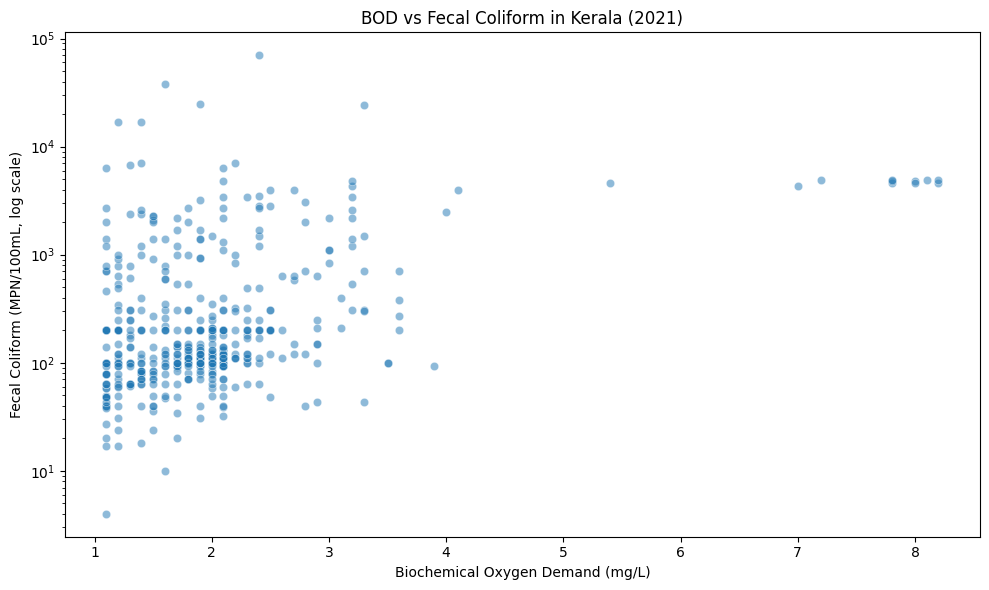

In [51]:
bod_fc = df.dropna(
    subset=[
        "Biochemical Oxygen Demand (mg/L)",
        "Fecal Coliform (MPN/100mL)"
    ]
).copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=bod_fc,
    x="Biochemical Oxygen Demand (mg/L)",
    y="Fecal Coliform (MPN/100mL)",
    alpha=0.5
)

plt.yscale("log")
plt.title("BOD vs Fecal Coliform in Kerala (2021)")
plt.xlabel("Biochemical Oxygen Demand (mg/L)")
plt.ylabel("Fecal Coliform (MPN/100mL, log scale)")
plt.tight_layout()
plt.show()

### Relationship Between BOD and Fecal Coliform

The scatter plot shows considerable variation in Fecal Coliform measurements across similar BOD concentrations. Most observations are concentrated around BOD values between 1 and 2.5 mg/L, while Fecal Coliform measurements span several orders of magnitude. No clear linear relationship is visually apparent. This observation is consistent with the weak positive correlation identified in the correlation heatmap (0.16). High-value observations and missing data may influence the observed pattern.

### District-wise Fecal Coliform Analysis

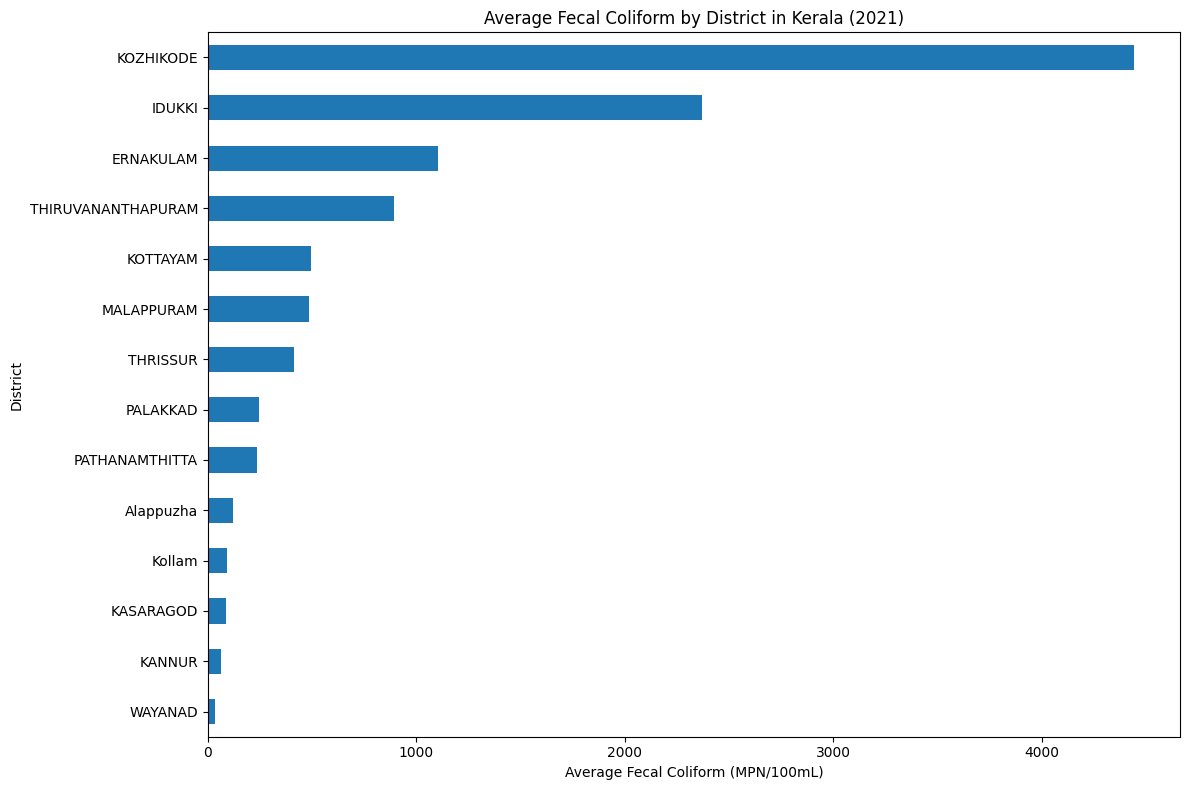

In [52]:
district_fc = df.dropna(
    subset=[
        "District",
        "Fecal Coliform (MPN/100mL)"
    ]
).copy()

district_fc_avg = district_fc.groupby("District")[
    "Fecal Coliform (MPN/100mL)"
].mean().sort_values()

plt.figure(figsize=(12, 8))

district_fc_avg.plot(kind="barh")

plt.title("Average Fecal Coliform by District in Kerala (2021)")
plt.xlabel("Average Fecal Coliform (MPN/100mL)")
plt.ylabel("District")
plt.tight_layout()
plt.show()

### District-wise Fecal Coliform Analysis

The district-wise comparison reveals considerable variation in average Fecal Coliform concentrations across Kerala. Kozhikode recorded the highest average concentration, followed by Idukki and Ernakulam. Wayanad showed the lowest average among the districts represented. These differences indicate spatial variability in the recorded microbial measurements. However, district averages may be influenced by monitoring station coverage, observation counts, and extreme values. Therefore, the results should not be interpreted as definitive rankings of overall district water quality.

## Summary of Exploratory Data Analysis

The exploratory data analysis of Kerala water quality monitoring data for 2021 revealed considerable variation in water quality measurements across districts, monitoring stations, and months. The dataset contains 1,155 observations collected from 129 monitoring stations. Descriptive statistics and distribution plots highlighted variability in Biochemical Oxygen Demand (BOD), Fecal Coliform (FC), and Total Coliform (TC) measurements, along with the presence of high-value observations.

District-wise analysis revealed differences in recorded BOD and Fecal Coliform concentrations, while station-wise and district-wise observation counts indicated uneven monitoring coverage. Monthly BOD averages fluctuated throughout the year, whereas monthly FC and TC boxplots showed substantial variability in microbial measurements. Logarithmic scales were useful for visualizing the wide range of FC and TC values.

Correlation analysis indicated a strong positive correlation between Fecal Coliform and Total Coliform (0.81), a weak positive correlation between BOD and Fecal Coliform (0.16), and a negligible negative correlation between BOD and Total Coliform (-0.03). The BOD–FC scatter plot showed considerable variation without an obvious linear pattern.

Missing measurements, particularly for Total Coliform, and uneven monitoring coverage limit the representativeness of these findings. Overall, the EDA provides an initial understanding of water quality patterns and highlights the importance of careful preprocessing and further analysis before drawing conclusions about pollution levels.